# Caso 05: RutaSabor — Cocina Fantasma: ¿Dónde Está el Margen?
## Día 3: El Ranking de Superficie (Mañana) y La Primera Grieta del Canal (Tarde)

**Objetivo de hoy:**
1. **Día 3 (Mañana) — Bajar del GMV al Margen Bruto:**
   - Aplicar el patrón *"agregar y pegar"* mediante CTEs: agregar el coste de ingredientes a nivel de pedido (`lineas_pedido` $\\times$ `productos`) y cruzarlo con `pedidos`.
   - Comparar el **Margen Bruto Medio** (calidad) frente al **Beneficio Bruto Total** (volumen). Entender por qué La Brasa Burger sigue coronándose en superficie.
   - Atender el contexto de los stakeholders sin perder el eje: GMV por ciudad (Gonzalo) y tiempos de entrega por cocina (corazonada de Bea sobre Vallecas).
2. **Día 3 (Tarde) — La Primera Grieta: La Comisión del Marketplace:**
   - Restar el socio invisible que cobra sin cocinar: la comisión de cada plataforma (Glovo 30%, Uber Eats 28%, Just Eat 25%, App propia 6%).
   - Calcular el **Margen Neto de Comisión** por pedido y en total.
   - Destripar el **Mix de Canales** con funciones de ventana (`PARTITION BY marca`) para explicar por qué La Brasa se desmorona mientras Poke Break aguanta.


In [1]:
import pandas as pd
import numpy as np
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

CLEAN_DIR = os.path.join('data', 'clean')
REPORTS_DIR = 'reports'
os.makedirs(REPORTS_DIR, exist_ok=True)

# Configuración visual ejecutiva
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

con = duckdb.connect()
# Registro de vistas limpias
con.execute(f"CREATE VIEW pedidos AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'pedidos.parquet')}'")
con.execute(f"CREATE VIEW lineas_pedido AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'lineas_pedido.parquet')}'")
con.execute(f"CREATE VIEW productos AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'productos.parquet')}'")
con.execute(f"CREATE VIEW marcas AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'marcas.parquet')}'")
con.execute(f"CREATE VIEW canales AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'canales.parquet')}'")
con.execute(f"CREATE VIEW cocinas AS SELECT * FROM '{os.path.join(CLEAN_DIR, 'cocinas.parquet')}'")

print("Vistas DuckDB registradas con éxito.")


Vistas DuckDB registradas con éxito.


### 1. Margen Bruto por Marca: Patrón "Agregar y Pegar"

El coste de ingredientes vive en el detalle (`lineas_pedido`), pero debe restarse a nivel de `pedidos`.
Construimos una CTE que suma `cantidad * coste_ingredientes` por pedido y la unimos a la tabla central.


In [2]:
query_margen_bruto = """
WITH ingredientes_pedido AS (
    SELECT 
        lp.pedido_id,
        SUM(lp.cantidad * pr.coste_ingredientes) AS coste_ingredientes
    FROM lineas_pedido lp
    JOIN productos pr ON lp.producto_id = pr.producto_id
    GROUP BY lp.pedido_id
)
SELECT 
    m.nombre AS marca,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(p.importe_cobrado), 2) AS ticket_medio_eur,
    ROUND(AVG(ip.coste_ingredientes), 2) AS coste_ingredientes_medio_eur,
    ROUND(AVG(p.importe_cobrado - ip.coste_ingredientes), 2) AS margen_bruto_medio_eur,
    ROUND(SUM(p.importe_cobrado - ip.coste_ingredientes), 2) AS beneficio_bruto_total_eur,
    ROUND(SUM(p.importe_cobrado - ip.coste_ingredientes) * 100.0 / SUM(SUM(p.importe_cobrado - ip.coste_ingredientes)) OVER (), 2) AS cuota_beneficio_bruto_pct
FROM pedidos p
JOIN ingredientes_pedido ip ON p.pedido_id = ip.pedido_id
JOIN marcas m ON p.marca_id = m.marca_id
GROUP BY m.nombre
ORDER BY beneficio_bruto_total_eur DESC;
"""

df_bruto = con.execute(query_margen_bruto).df()
print("=== RANKING DE MARGEN BRUTO POR MARCA ===")
df_bruto


=== RANKING DE MARGEN BRUTO POR MARCA ===


,marca,total_pedidos,ticket_medio_eur,coste_ingredientes_medio_eur,margen_bruto_medio_eur,beneficio_bruto_total_eur,cuota_beneficio_bruto_pct
0,La Brasa Burger,50978,11.52,7.06,4.46,227142.95,30.18
1,Pizza Nostra,25428,13.61,7.24,6.37,161896.11,21.51
2,Poke Break,21001,15.83,9.10,6.73,141321.09,18.77
3,Wok Express,25496,11.48,6.09,5.38,137287.22,18.24
4,Dulce Antojo,27097,6.51,3.37,3.14,85074.41,11.30


**La trampa del Beneficio Bruto Total:**
* **Calidad vs Volumen:**
  * En **margen unitario por pedido**, Poke Break lidera con **6,73 €** y Pizza Nostra con **6,37 €**, mientras que La Brasa Burger deja solo **4,46 €**.
  * Sin embargo, al multiplicar por sus 50.978 pedidos, La Brasa genera **227.142,95 €** de beneficio bruto total (**34,80% del total de la empresa**).
* Para Gonzalo y el departamento de Compras, esto parece una victoria incuestionable: *"Mucho por poco es más que poco por mucho"*.
* **El error de quedarse aquí:** El beneficio bruto aún ignora los dos costes invisibles: la comisión del canal y las incidencias.


### 2. Atendiendo el Contexto: Peticiones de Gonzalo y Bea

* **Petición de Gonzalo:** ¿Cómo se reparte el GMV por ciudad?
* **Corazonada de Bea (Operaciones):** *"Vallecas va lenta y ahí están los pedidos malos"*. Analizamos los tiempos de entrega promedio por cocina.


In [3]:
query_ciudades = """
SELECT 
    c.ciudad,
    COUNT(*) AS total_pedidos,
    ROUND(SUM(p.importe_cobrado), 2) AS gmv_total_eur,
    ROUND(AVG(p.importe_cobrado), 2) AS ticket_medio_eur
FROM pedidos p
JOIN cocinas c ON p.cocina_id = c.cocina_id
GROUP BY c.ciudad
ORDER BY gmv_total_eur DESC;
"""
print("=== GMV POR CIUDAD (GONZALO) ===")
df_ciudades = con.execute(query_ciudades).df()
display(df_ciudades)

query_tiempos_cocina = """
SELECT 
    c.cocina_id,
    c.nombre AS cocina,
    c.ciudad,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(p.tiempo_entrega_min), 2) AS tiempo_medio_min
FROM pedidos p
JOIN cocinas c ON p.cocina_id = c.cocina_id
GROUP BY c.cocina_id, c.nombre, c.ciudad
ORDER BY tiempo_medio_min DESC;
"""
print("\n=== TIEMPOS POR COCINA (BEA) ===")
df_tiempos = con.execute(query_tiempos_cocina).df()
display(df_tiempos)


=== GMV POR CIUDAD (GONZALO) ===


,ciudad,total_pedidos,gmv_total_eur,ticket_medio_eur
0,Madrid,67460,779886.81,11.56
1,Barcelona,43717,506988.49,11.60
2,Zaragoza,20840,241565.65,11.59
3,Valencia,17983,206398.60,11.48



=== TIEMPOS POR COCINA (BEA) ===


,cocina_id,cocina,ciudad,total_pedidos,tiempo_medio_min
0,6,Sants,Barcelona,15098,34.76
1,8,Ruzafa,Valencia,10423,34.72
2,7,Gracia,Barcelona,12024,34.71
3,1,Chamberi,Madrid,22570,34.71
4,3,Tetuan,Madrid,15102,34.65
5,9,Campanar,Valencia,7560,34.63
6,5,Poblenou,Barcelona,16595,34.60
7,4,Arganzuela,Madrid,13445,34.59
8,2,Vallecas,Madrid,16343,34.56
9,10,Delicias,Zaragoza,20840,34.55


**Lección de oficio: Distinguir el Eje del Contexto:**
1. **GMV por Ciudad:** Madrid concentra el 45% del GMV (779.886 €), seguido de Barcelona (506.988 €). Es un contexto valioso para Clara, pero no decide qué marca clonar.
2. **Tiempos en Vallecas:** El tiempo medio de entrega en Vallecas es de **34,56 minutos**, prácticamente idéntico al de Chamberí (34,71 min) o Sants (34,76 min). La corazonada de Bea sobre la lentitud operativa de Vallecas queda descartada en los datos. No dejamos que desvíe el eje principal: la rentabilidad de las marcas.


## Día 3 (Tarde) — La Primera Grieta: La Comisión del Marketplace

Cada pedido que entra por marketplace paga entre el **25% y el 30%** a la plataforma, mientras que la **App propia** solo asume el **6%** de pasarela de pago.
Restamos este coste al margen bruto para obtener el **Margen Neto de Comisión**:
$$\\text{Margen Neto Comisión} = \\text{Margen Bruto} - (\\text{Importe Cobrado} \\times \\text{Comisión Canal})$$


In [4]:
query_neto_comision = """
WITH ingredientes_pedido AS (
    SELECT 
        lp.pedido_id,
        SUM(lp.cantidad * pr.coste_ingredientes) AS coste_ingredientes
    FROM lineas_pedido lp
    JOIN productos pr ON lp.producto_id = pr.producto_id
    GROUP BY lp.pedido_id
)
SELECT 
    m.nombre AS marca,
    COUNT(*) AS total_pedidos,
    ROUND(AVG(p.importe_cobrado - ip.coste_ingredientes), 2) AS margen_bruto_medio_eur,
    ROUND(AVG(p.importe_cobrado * can.comision_pct), 2) AS comision_media_eur,
    ROUND(AVG(p.importe_cobrado - ip.coste_ingredientes - (p.importe_cobrado * can.comision_pct)), 2) AS margen_neto_medio_eur,
    ROUND(SUM(p.importe_cobrado - ip.coste_ingredientes - (p.importe_cobrado * can.comision_pct)), 2) AS margen_neto_total_eur,
    ROUND(SUM(p.importe_cobrado - ip.coste_ingredientes - (p.importe_cobrado * can.comision_pct)) * 100.0 / 
          SUM(SUM(p.importe_cobrado - ip.coste_ingredientes - (p.importe_cobrado * can.comision_pct))) OVER (), 2) AS cuota_margen_neto_pct
FROM pedidos p
JOIN ingredientes_pedido ip ON p.pedido_id = ip.pedido_id
JOIN marcas m ON p.marca_id = m.marca_id
JOIN canales can ON p.canal_id = can.canal_id
GROUP BY m.nombre
ORDER BY margen_neto_total_eur DESC;
"""

df_neto = con.execute(query_neto_comision).df()
print("=== RANKING DE MARGEN NETO DE COMISIÓN ===")
df_neto


=== RANKING DE MARGEN NETO DE COMISIÓN ===


,marca,total_pedidos,margen_bruto_medio_eur,comision_media_eur,margen_neto_medio_eur,margen_neto_total_eur,cuota_margen_neto_pct
0,Poke Break,21001,6.73,3.01,3.72,78176.64,24.64
1,Pizza Nostra,25428,6.37,3.42,2.95,74957.56,23.63
2,La Brasa Burger,50978,4.46,3.26,1.19,60869.90,19.19
3,Wok Express,25496,5.38,3.02,2.37,60301.17,19.01
4,Dulce Antojo,27097,3.14,1.56,1.58,42928.83,13.53


**¡Se abre la primera gran grieta!**
1. **El desplome de La Brasa Burger:**
   * Su margen medio cae de **4,46 € a 1,19 €** por pedido (pierde **3,26 €**, o un 73% de su margen bruto en manos del marketplace).
   * En beneficio neto total cae de **227.142 € a 60.869 €**, pasando del **1º al 3º puesto**.
2. **El aguante de Poke Break:**
   * Su margen medio pasa de **6,73 € a 3,72 €** (retiene más del 55% de su margen bruto).
   * Pasa a liderar el beneficio neto total con **78.176 €** pese a tener menos de la mitad de pedidos que La Brasa.


### 3. La Causa Raíz: Mix de Canales por Marca (`PARTITION BY`)

Para entender por qué unas marcas se desinflan y otras aguantan, usamos una función de ventana:
`COUNT(*) OVER (PARTITION BY marca)` para calcular qué porcentaje de pedidos de cada marca se vende por cada canal sin perder el desglose.


In [5]:
query_mix_canales = """
SELECT 
    m.nombre AS marca,
    can.nombre AS canal,
    COUNT(*) AS pedidos_canal,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (PARTITION BY m.nombre), 1) AS pct_canal_en_marca
FROM pedidos p
JOIN marcas m ON p.marca_id = m.marca_id
JOIN canales can ON p.canal_id = can.canal_id
GROUP BY m.nombre, can.nombre
ORDER BY m.nombre, pct_canal_en_marca DESC;
"""

df_mix = con.execute(query_mix_canales).df()
df_mix_pivot = df_mix.pivot(index='marca', columns='canal', values='pct_canal_en_marca').fillna(0)
print("=== MIX DE CANAL POR MARCA (% de pedidos) ===")
df_mix_pivot[['glovo', 'uber_eats', 'just_eat', 'app_propia']]


=== MIX DE CANAL POR MARCA (% de pedidos) ===

canal,glovo,uber_eats,just_eat,app_propia
marca,,,,
Dulce Antojo,39.1,25.4,15.4,20.2
La Brasa Burger,68.1,21.9,6.1,3.9
Pizza Nostra,44.7,25.0,15.2,15.1
Poke Break,27.7,19.9,10.2,42.2
Wok Express,49.9,25.0,15.0,10.1


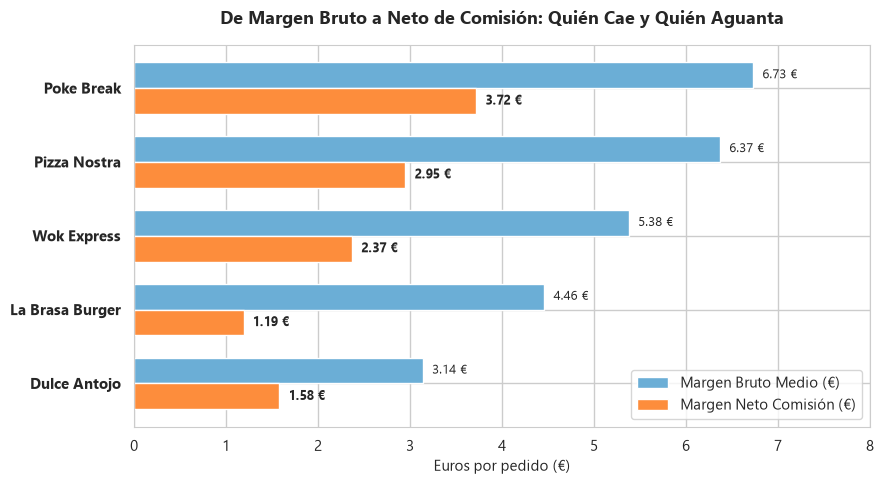

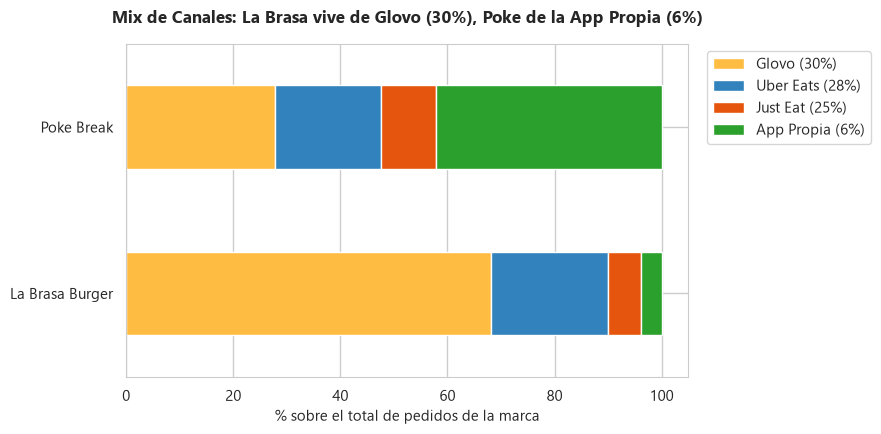

In [6]:
# Gráfico 1: De Bruto a Neto de Comisión (Quién cae y quién aguanta)
fig, ax = plt.subplots(figsize=(9, 5))

df_plot = df_neto.sort_values('margen_bruto_medio_eur', ascending=True)
y = np.arange(len(df_plot))
height = 0.35

ax.barh(y + height/2, df_plot['margen_bruto_medio_eur'], height, label='Margen Bruto Medio (€)', color='#6baed6')
ax.barh(y - height/2, df_plot['margen_neto_medio_eur'], height, label='Margen Neto Comisión (€)', color='#fd8d3c')

ax.set_yticks(y)
ax.set_yticklabels(df_plot['marca'], fontsize=11, fontweight='bold')
ax.set_xlabel('Euros por pedido (€)', fontsize=11)
ax.set_title('De Margen Bruto a Neto de Comisión: Quién Cae y Quién Aguanta', fontsize=13, fontweight='bold', pad=15)
ax.legend(frameon=True, loc='lower right')
ax.set_xlim(0, 8)

for i, row in enumerate(df_plot.itertuples()):
    ax.text(row.margen_bruto_medio_eur + 0.1, i + height/2, f"{row.margen_bruto_medio_eur:.2f} €", va='center', fontsize=9)
    ax.text(row.margen_neto_medio_eur + 0.1, i - height/2, f"{row.margen_neto_medio_eur:.2f} €", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_03_bruto_vs_neto.png'), dpi=300)
plt.show()

# Gráfico 2: Mix de Canales (La Brasa vs Poke Break)
fig, ax = plt.subplots(figsize=(9, 4.5))
mix_comparado = df_mix_pivot.loc[['La Brasa Burger', 'Poke Break'], ['glovo', 'uber_eats', 'just_eat', 'app_propia']]
colores = ['#ffbc42', '#3182bd', '#e6550d', '#2ca02c']
mix_comparado.plot(kind='barh', stacked=True, ax=ax, color=colores, width=0.5)

ax.set_title('Mix de Canales: La Brasa vive de Glovo (30%), Poke de la App Propia (6%)', fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel('% sobre el total de pedidos de la marca', fontsize=11)
ax.set_ylabel('')
ax.legend(['Glovo (30%)', 'Uber Eats (28%)', 'Just Eat (25%)', 'App Propia (6%)'], bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(REPORTS_DIR, 'dia_03_mix_canales.png'), dpi=300)
plt.show()


### Conclusión del Día 3:
* **El hallazgo técnico y de negocio:**
  * La Brasa concentra el **68,1% de sus ventas en Glovo** (el canal con la comisión más voraz: 30%) y apenas un **3,9% en la App propia**.
  * Poke Break, por el contrario, canaliza el **42,2% de sus pedidos por la App propia** (donde la comisión es solo del 6%).
* **Advertencia de Irene Vidal:**
  * *"La comisión es solo media respuesta. No te quedes aquí. Mañana en el Día 4 agregamos el segundo coste oculto: las incidencias y compensaciones. Y calcularemos la Cuota de Contribución para comprobar qué parte del beneficio neto total aporta realmente cada marca."*
